In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from google.colab import files
uploaded = files.upload()

Saving IFND.csv to IFND.csv


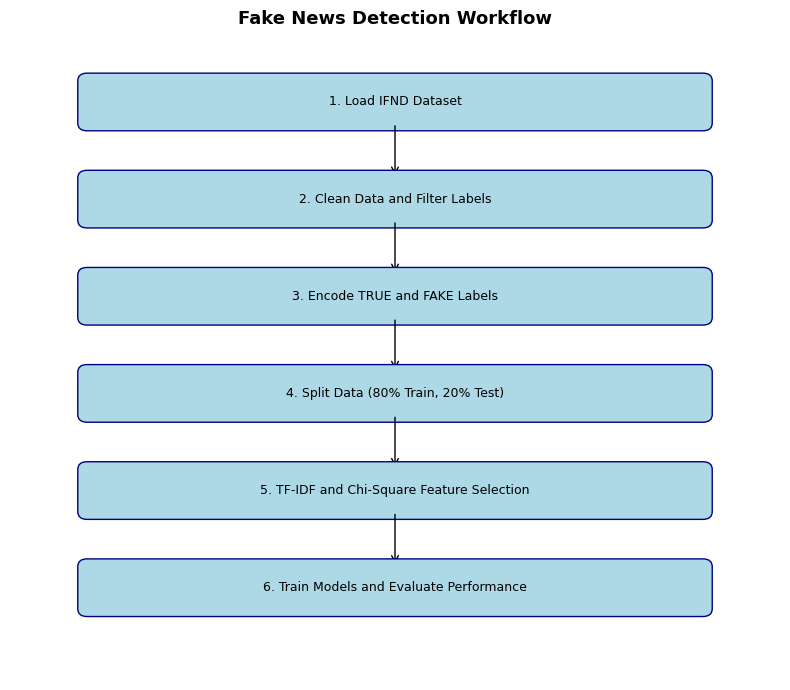

In [2]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

steps = [
    "1. Load IFND Dataset",
    "2. Clean Data and Filter Labels",
    "3. Encode TRUE and FAKE Labels",
    "4. Split Data (80% Train, 20% Test)",
    "5. TF-IDF and Chi-Square Feature Selection",
    "6. Train Models and Evaluate Performance"
]

ys = [8.6, 7.1, 5.6, 4.1, 2.6, 1.1]

for i, (step, y) in enumerate(zip(steps, ys)):
    box = FancyBboxPatch(
        (1, y), 8, 0.65,
        boxstyle="round,pad=0.12",
        facecolor="lightblue",
        edgecolor="navy"
    )
    ax.add_patch(box)
    ax.text(5, y + 0.325, step,
            ha="center", va="center", fontsize=9)

    if i < len(steps) - 1:
        ax.add_patch(FancyArrowPatch(
            (5, y), (5, ys[i + 1] + 0.65),
            arrowstyle="->", mutation_scale=12,
            color="black"
        ))

ax.set_title("Fake News Detection Workflow",
             fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()


In [3]:
df = pd.read_csv("IFND.csv", encoding="latin1")

print(df.head())
print(df.columns)
print(df.shape)

   id                                          Statement  \
0   2  WHO praises India's Aarogya Setu app, says it ...   
1   3  In Delhi, Deputy US Secretary of State Stephen...   
2   4  LAC tensions: China's strategy behind delibera...   
3   5  India has signed 250 documents on Space cooper...   
4   6  Tamil Nadu chief minister's mother passes away...   

                                               Image       Web  Category  \
0  https://cdn.dnaindia.com/sites/default/files/s...  DNAINDIA  COVID-19   
1  https://cdn.dnaindia.com/sites/default/files/s...  DNAINDIA  VIOLENCE   
2  https://cdn.dnaindia.com/sites/default/files/s...  DNAINDIA    TERROR   
3  https://cdn.dnaindia.com/sites/default/files/s...  DNAINDIA  COVID-19   
4  https://cdn.dnaindia.com/sites/default/files/s...  DNAINDIA  ELECTION   

     Date Label  
0  Oct-20  TRUE  
1  Oct-20  TRUE  
2  Oct-20  TRUE  
3  Oct-20  TRUE  
4  Oct-20  TRUE  
Index(['id', 'Statement', 'Image', 'Web', 'Category', 'Date', 'Label'], dt

In [4]:
# Define variable descriptions
descriptions = {
    "id": {
        "Unit": "Unique identifier",
        "Use": "Identifies each record"
    },
    "Statement": {
        "Unit": "Text",
        "Use": "News statement"
    },
    "Image": {
        "Unit": "Image / URL / file reference",
        "Use": "Provides associated visual information, if available"
    },
    "Category": {
        "Unit": "Categorical",
        "Use": "Groups claims by category"
    },
    "Date": {
        "Unit": "Date",
        "Use": "Records the date associated with the claim"
    },
    "Label": {
        "Unit": "Class label",
        "Use": "Indicates the assigned fact-checking label"
    }
}

# Build the table using columns that actually exist
rows = []

for col in df.columns:
    missing_pct = df[col].isna().mean() * 100

    info = descriptions.get(col, {
        "Unit": "Metadata / dataset-specific",
        "Use": "Provides additional information about the record"
    })

    rows.append({
        "Variable": col,
        "Unit": info["Unit"],
        "Missing %": round(missing_pct, 2),
        "Use": info["Use"]
    })

table1 = pd.DataFrame(rows)

# Display the table
display(table1)


,Variable,Unit,Missing %,Use
0,id,Unique identifier,0.00,Identifies each record
1,Statement,Text,0.00,News statement
2,Image,Image / URL / file reference,0.00,"Provides associated visual information, if ava..."
3,Web,Metadata / dataset-specific,0.00,Provides additional information about the record
4,Category,Categorical,0.00,Groups claims by category
5,Date,Date,19.96,Records the date associated with the claim
6,Label,Class label,0.00,Indicates the assigned fact-checking label


In [5]:
styled_table = (
    table1.style
    .format({"Missing %": "{:.2f}%"} )
    .set_caption("Table 1. Description of variables in the IFND dataset")
    .hide(axis="index")
)

display(styled_table)

Variable,Unit,Missing %,Use
id,Unique identifier,0.00%,Identifies each record
Statement,Text,0.00%,News statement
Image,Image / URL / file reference,0.00%,"Provides associated visual information, if available"
Web,Metadata / dataset-specific,0.00%,Provides additional information about the record
Category,Categorical,0.00%,Groups claims by category
Date,Date,19.96%,Records the date associated with the claim
Label,Class label,0.00%,Indicates the assigned fact-checking label


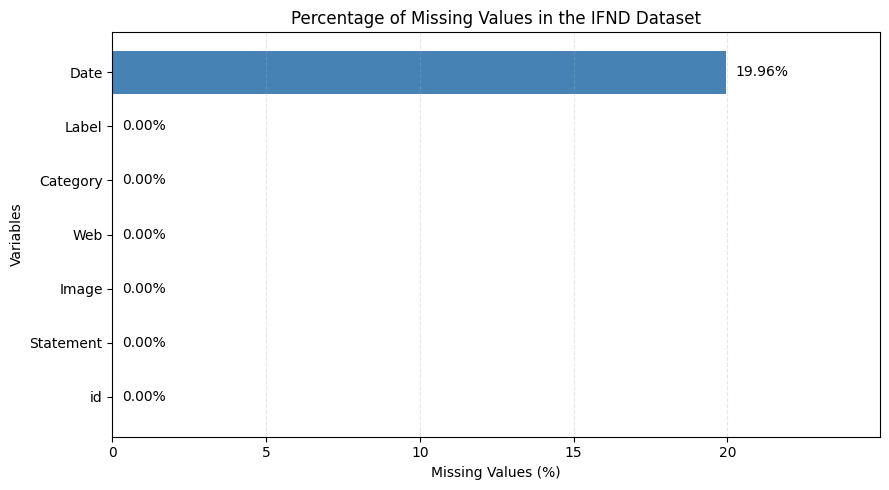

In [6]:
# Use the existing missing-values table
plot_data = table1.sort_values("Missing %", ascending=True)

plt.figure(figsize=(9, 5))

bars = plt.barh(
    plot_data["Variable"],
    plot_data["Missing %"],
    color=[
        "steelblue" if value > 0 else "lightgray"
        for value in plot_data["Missing %"]
    ]
)

# Add percentage labels
for bar, value in zip(bars, plot_data["Missing %"]):
    plt.text(
        value + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

plt.xlabel("Missing Values (%)")
plt.ylabel("Variables")
plt.title("Percentage of Missing Values in the IFND Dataset")
plt.xlim(0, max(plot_data["Missing %"].max() + 5, 5))
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:
df = df[["Statement", "Label"]]

df = df.dropna()

df["Statement"] = df["Statement"].astype(str)

print(df.head())
print(df["Label"].value_counts())

                                           Statement Label
0  WHO praises India's Aarogya Setu app, says it ...  TRUE
1  In Delhi, Deputy US Secretary of State Stephen...  TRUE
2  LAC tensions: China's strategy behind delibera...  TRUE
3  India has signed 250 documents on Space cooper...  TRUE
4  Tamil Nadu chief minister's mother passes away...  TRUE
Label
TRUE    37800
Fake    18914
Name: count, dtype: int64


In [8]:
df["Label"] = df["Label"].astype(str).str.strip().str.upper()

df = df[df["Label"].isin(["TRUE", "FAKE"])]

df["Label"] = df["Label"].map({
    "TRUE": 0,
    "FAKE": 1
})

print(df["Label"].value_counts())

Label
0    37800
1    18914
Name: count, dtype: int64


In [9]:
X = df["Statement"]
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 45371
Testing data: 11343


In [10]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (45371, 5000)
Testing feature shape: (11343, 5000)


In [11]:
k = min(2000, X_train_tfidf.shape[1])

selector = SelectKBest(score_func=chi2, k=k)

X_train_selected = selector.fit_transform(
    X_train_tfidf, y_train
)

X_test_selected = selector.transform(X_test_tfidf)

print("Features before selection:", X_train_tfidf.shape[1])
print("Features after selection:", X_train_selected.shape[1])

Features before selection: 5000
Features after selection: 2000


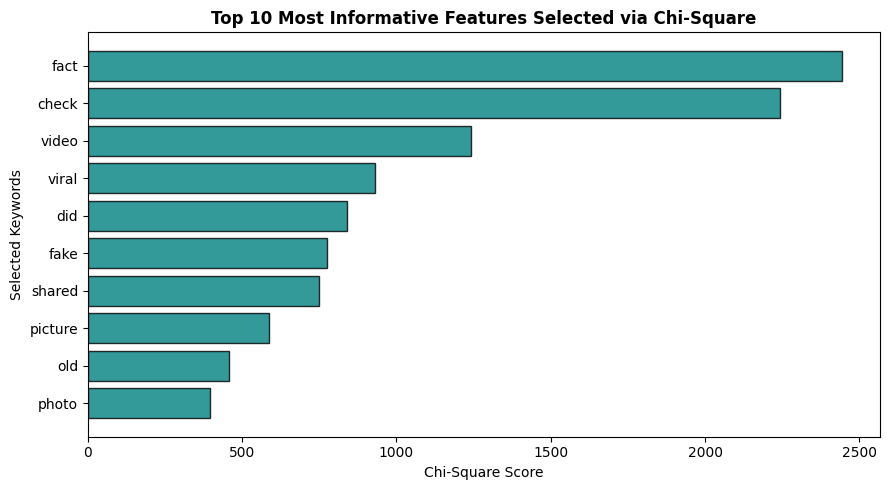

In [12]:
# Extract selected features and their scores
feature_names = tfidf.get_feature_names_out()
selected_mask = selector.get_support()
selected_features = feature_names[selected_mask]
feature_scores = selector.scores_[selected_mask]

# Get the top 10 highest-scoring features
top_indices = np.argsort(feature_scores)[-10:]
top_features = selected_features[top_indices]
top_scores = feature_scores[top_indices]

plt.figure(figsize=(9, 5))
plt.barh(top_features, top_scores, color="teal", edgecolor="black", alpha=0.8)
plt.xlabel("Chi-Square Score", fontsize=10)
plt.ylabel("Selected Keywords", fontsize=10)
plt.title("Top 10 Most Informative Features Selected via Chi-Square", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [13]:
models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Linear SVM": LinearSVC(),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean"
    )
}

results = []

for name, model in models.items():

    print("Training", name)

    model.fit(X_train_selected, y_train)

    y_pred = model.predict(X_test_selected)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append([
        name, accuracy, precision, recall, f1
    ])

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\nModel Comparison:")
print(results_df.round(4))

Training Naive Bayes
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      7560
           1       0.94      0.87      0.90      3783

    accuracy                           0.94     11343
   macro avg       0.94      0.92      0.93     11343
weighted avg       0.94      0.94      0.94     11343

Training Logistic Regression
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      7560
           1       0.97      0.85      0.91      3783

    accuracy                           0.94     11343
   macro avg       0.95      0.92      0.93     11343
weighted avg       0.95      0.94      0.94     11343

Training Linear SVM
              precision    recall  f1-score   support

           0       0.94      0.98      0.96      7560
           1       0.96      0.88      0.92      3783

    accuracy                           0.95     11343
   macro avg       0.95      0.93      0.94     11343
weig

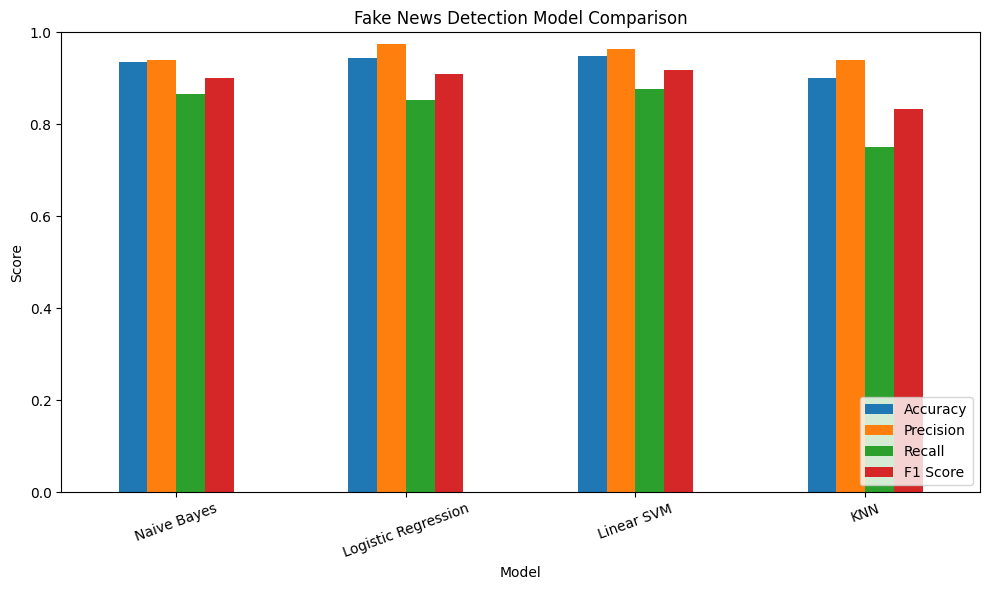

In [14]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Fake News Detection Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

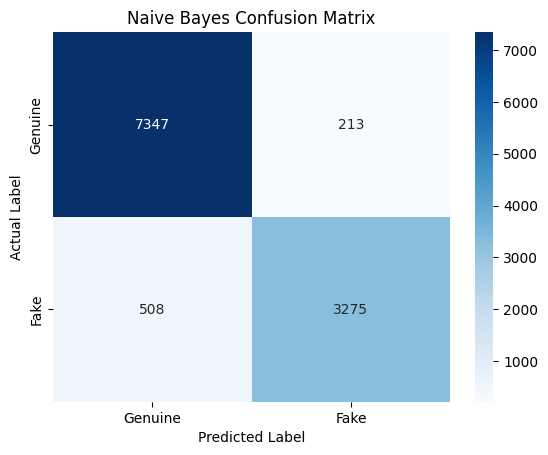

In [15]:
nb_model = models["Naive Bayes"]

y_pred_nb = nb_model.predict(X_test_selected)

cm = confusion_matrix(y_test, y_pred_nb)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Fake"],
    yticklabels=["Genuine", "Fake"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [16]:
headline = ["A new news headline from India"]

headline_tfidf = tfidf.transform(headline)
headline_selected = selector.transform(headline_tfidf)

prediction = nb_model.predict(headline_selected)

if prediction[0] == 1:
    print("Predicted News: Fake")
else:
    print("Predicted News: Genuine")

Predicted News: Fake
